In [1]:
import random
from qiskit import QuantumCircuit, transpile
import pyzx as zx
import importlib
from IPython.display import display
from qiskit.quantum_info import Operator

import qcGenerator
import pxOptimizer
import qiskitOptimizer
import mixOptimizers

# Reload the module files
importlib.reload(qcGenerator)
importlib.reload(pxOptimizer)
importlib.reload(qiskitOptimizer)
importlib.reload(mixOptimizers)

# Re-import the classes from the reloaded modules
from qcGenerator import QuantumCircuitGenerator
from pxOptimizer import PyZXOptimizer
from qiskitOptimizer import QiskitOptimizer
from mixOptimizers import PyZXThenQiskitOptimizer, QiskitThenPyZXOptimizer

In [2]:
from qiskitOptimizer import CLIFFORD_T_BASIS

def count_t_gates(qc: QuantumCircuit) -> int:
    # Translate to Clifford+T without optimising, so every circuit is counted the same way:
    # ccx costs 7 T, rz(k*pi/4) costs 1 T only for odd k, and T gates inside other gates are exposed
    ops = transpile(qc, basis_gates=CLIFFORD_T_BASIS, optimization_level=0).count_ops()
    return ops.get("t", 0) + ops.get("tdg", 0)

In [3]:
num_qubits = 3
depth = 20
# Qiskit level 2/3 re-synthesizes 2-qubit blocks and then approximates the resulting rotations,
# so some results are only approximately equal to the original. Level 1 keeps every result exact.
qiskit_level = 3
# NOTE: PyZX -> Qiskit always uses Qiskit level 1 (see PyZXThenQiskitOptimizer in mixOptimizers.py).
# At level 2/3 Qiskit re-synthesizes PyZX's output and inflates the T-count (e.g. 21 -> 397 T).

print("=== 1. Generating Random Quantum Circuit ===")
generator = QuantumCircuitGenerator(num_qubits=num_qubits, depth=depth)
original_qc = generator.generate()
print(f"Original circuit generated with {num_qubits} qubits and depth {depth}.")
print("Original gate breakdown:", original_qc.count_ops())
print(f"Original T-gate count: {count_t_gates(original_qc)}")

print("\n=== 2. Optimizing with Qiskit Tools Only ===")
qiskit_optimizer = QiskitOptimizer(optimization_level=qiskit_level)
qiskit_optimized_qc = qiskit_optimizer.optimize(original_qc)
print("Qiskit-optimized gate breakdown:", qiskit_optimized_qc.count_ops())
print(f"Qiskit-optimized T-gate count: {count_t_gates(qiskit_optimized_qc)}")

print("\n=== 3. Optimizing with PyZX (ZX-Calculus) Only ===")
pyzx_optimizer = PyZXOptimizer()
pyzx_optimized_qc = pyzx_optimizer.optimize(original_qc)
print("PyZX-optimized gate breakdown:", pyzx_optimized_qc.count_ops())
print(f"PyZX-optimized T-gate count: {count_t_gates(pyzx_optimized_qc)}")

print("\n=== 4. Hybrid: Qiskit -> Then PyZX ===")
qiskit_then_pyzx = QiskitThenPyZXOptimizer(optimization_level=qiskit_level)
qp_optimized_qc = qiskit_then_pyzx.optimize(original_qc)
print("Qiskit->PyZX gate breakdown:", qp_optimized_qc.count_ops())
print(f"Qiskit->PyZX T-gate count: {count_t_gates(qp_optimized_qc)}")

print("\n=== 5. Hybrid: PyZX -> Then Qiskit ===")
pyzx_then_qiskit = PyZXThenQiskitOptimizer()  # Qiskit level 1, see note above
pq_optimized_qc = pyzx_then_qiskit.optimize(original_qc)
print("PyZX->Qiskit gate breakdown:", pq_optimized_qc.count_ops())
print(f"PyZX->Qiskit T-gate count: {count_t_gates(pq_optimized_qc)}")

=== 1. Generating Random Quantum Circuit ===
Original circuit generated with 3 qubits and depth 20.
Original gate breakdown: OrderedDict({'t': 9, 'swap': 7, 'h': 5, 'cx': 5, 's': 5, 'x': 4, 'rz': 4, 'ccx': 3})
Original T-gate count: 31

=== 2. Optimizing with Qiskit Tools Only ===
Qiskit-optimized gate breakdown: OrderedDict({'cx': 23, 't': 13, 'tdg': 12, 'h': 9, 's': 3, 'x': 3, 'swap': 1})
Qiskit-optimized T-gate count: 25

=== 3. Optimizing with PyZX (ZX-Calculus) Only ===
PyZX-optimized gate breakdown: OrderedDict({'h': 43, 'rz': 25, 'cz': 21, 'cx': 11, 'swap': 2})
PyZX-optimized T-gate count: 23

=== 4. Hybrid: Qiskit -> Then PyZX ===
Qiskit->PyZX gate breakdown: OrderedDict({'h': 43, 'rz': 24, 'cz': 22, 'cx': 8, 'swap': 2})
Qiskit->PyZX T-gate count: 23

=== 5. Hybrid: PyZX -> Then Qiskit ===
PyZX->Qiskit gate breakdown: OrderedDict({'h': 83, 'cx': 38, 't': 15, 'tdg': 8, 'z': 8, 's': 5, 'x': 1})
PyZX->Qiskit T-gate count: 23


In [4]:
#display(original_qc.draw("mpl"))
# display(qiskit_optimized_qc.draw("mpl"))
# display(pyzx_optimized_qc.draw("mpl"))
# display(qp_optimized_qc.draw("mpl"))
# display(pq_optimized_qc.draw("mpl"))

In [5]:
# Create a circuit containing a Toffoli gate (which inherently requires T-gates)
qc = QuantumCircuit(3)
qc.ccx(0, 1, 2)  # Toffoli gate decomposes into T-gates

print("Original T-gate count:", count_t_gates(qc))

# Optimize with PyZX
pyzx_optimizer = PyZXOptimizer()

optimized_qc = pyzx_optimizer.optimize(qc)

print("PyZX Optimized T-gate count:", count_t_gates(optimized_qc))
print("Gate breakdown after PyZX:", optimized_qc.count_ops())

Original T-gate count: 7
PyZX Optimized T-gate count: 7
Gate breakdown after PyZX: OrderedDict({'h': 14, 'cz': 10, 'rz': 7, 'swap': 1})


In [6]:
from qiskit import QuantumCircuit, transpile
from qiskitOptimizer import QiskitOptimizer



# 1. Create original circuit and explicitly decompose it
qc = QuantumCircuit(3)
qc.ccx(0, 1, 2)

# Use .decompose() to unpack high-level blocks like ccx
unrolled_original = qc.decompose()

print("Original T-gate count (unrolled):", count_t_gates(unrolled_original))
print("Original gate breakdown:", unrolled_original.count_ops())

# 2. Optimize with Qiskit Optimizer at Level 3, specifying target basis gates 
# so it is forced to unroll and optimize down to primitives
qiskit_optimizer = QiskitOptimizer(optimization_level=3)
# Alternatively, ensure your QiskitOptimizer passes basis_gates if needed, 
# or decompose before passing to the optimizer:
optimized_qc = qiskit_optimizer.optimize(qc.decompose())

print("\nQiskit Level 3 Optimized T-gate count:", count_t_gates(optimized_qc))
print("Gate breakdown after Qiskit:", optimized_qc.count_ops())

Original T-gate count (unrolled): 7
Original gate breakdown: OrderedDict({'cx': 6, 't': 4, 'tdg': 3, 'h': 2})

Qiskit Level 3 Optimized T-gate count: 7
Gate breakdown after Qiskit: OrderedDict({'cx': 6, 't': 4, 'tdg': 3, 'h': 2})


In [7]:
import numpy as np

# A single random circuit says little; compare T-counts over many seeded circuits
num_circuits = 50
optimizers = {
    "Qiskit only": QiskitOptimizer(optimization_level=qiskit_level),
    "PyZX only": PyZXOptimizer(),
    "Qiskit -> PyZX": QiskitThenPyZXOptimizer(optimization_level=qiskit_level),
    "PyZX -> Qiskit": PyZXThenQiskitOptimizer(),  # Qiskit level 1
}
t_counts = {"Original": []} | {name: [] for name in optimizers}

for seed in range(num_circuits):
    random.seed(seed)
    circuit = QuantumCircuitGenerator(num_qubits=num_qubits, depth=depth).generate()
    t_counts["Original"].append(count_t_gates(circuit))
    for name, optimizer in optimizers.items():
        t_counts[name].append(count_t_gates(optimizer.optimize(circuit)))

for name, counts in t_counts.items():
    print(f"{name:15s} mean T-count: {np.mean(counts):6.2f}   min: {min(counts):3d}   max: {max(counts):3d}")

Original        mean T-count:  30.92   min:  11   max:  74
Qiskit only     mean T-count:  21.00   min:   3   max:  54
PyZX only       mean T-count:  12.12   min:   3   max:  32
Qiskit -> PyZX  mean T-count:  12.12   min:   3   max:  32
PyZX -> Qiskit  mean T-count:  12.12   min:   3   max:  32


qubits 5: circuit 1/10 done (0.1 min elapsed)
qubits 5: circuit 2/10 done (0.1 min elapsed)
qubits 5: circuit 3/10 done (0.2 min elapsed)
qubits 5: circuit 4/10 done (0.2 min elapsed)
qubits 5: circuit 5/10 done (0.3 min elapsed)
qubits 5: circuit 6/10 done (0.4 min elapsed)
qubits 5: circuit 7/10 done (0.5 min elapsed)
qubits 5: circuit 8/10 done (0.6 min elapsed)
qubits 5: circuit 9/10 done (0.6 min elapsed)
qubits 5: circuit 10/10 done (0.7 min elapsed)
qubits 10: circuit 1/10 done (1.0 min elapsed)
qubits 10: circuit 2/10 done (1.3 min elapsed)
qubits 10: circuit 3/10 done (1.6 min elapsed)
qubits 10: circuit 4/10 done (1.9 min elapsed)
qubits 10: circuit 5/10 done (2.1 min elapsed)
qubits 10: circuit 6/10 done (2.4 min elapsed)
qubits 10: circuit 7/10 done (2.7 min elapsed)
qubits 10: circuit 8/10 done (3.0 min elapsed)
qubits 10: circuit 9/10 done (3.3 min elapsed)
qubits 10: circuit 10/10 done (3.6 min elapsed)
qubits 15: circuit 1/10 done (4.1 min elapsed)
qubits 15: circuit 2/

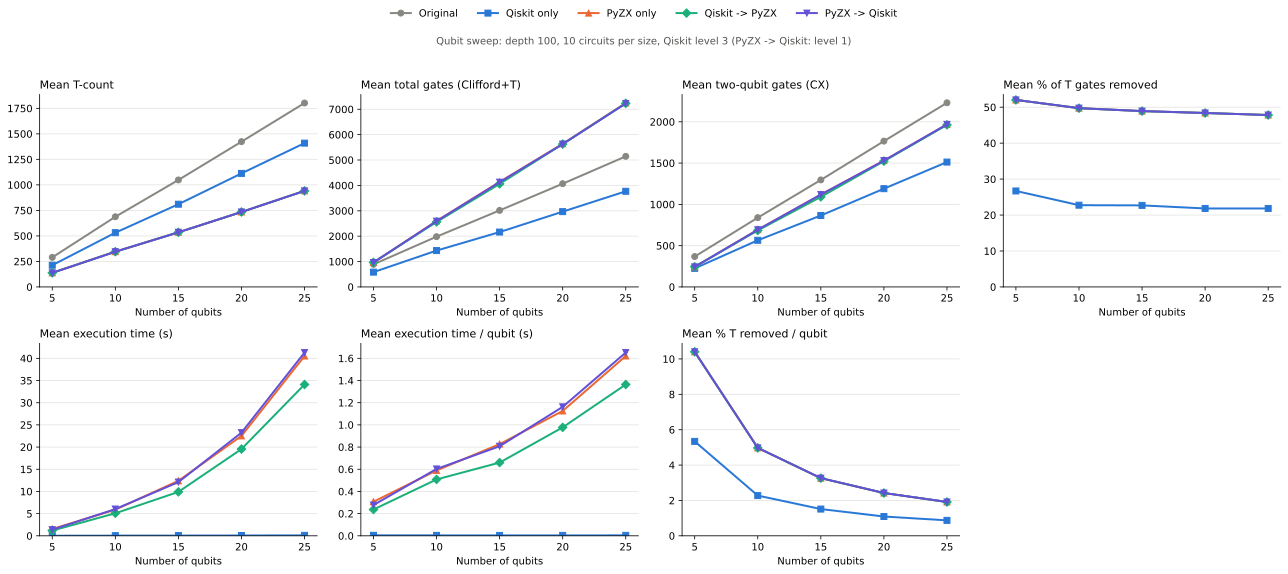

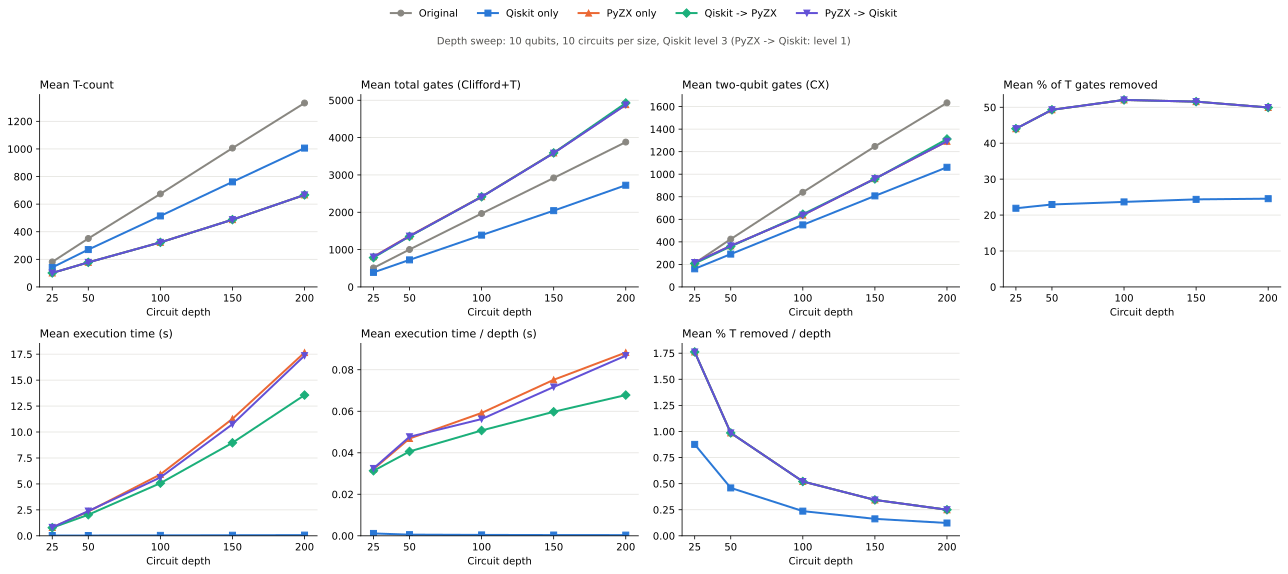

Saved circuits, results.json, summary.csv, runs.csv, graph_qubits.png and graph_depth.png to results\2026-10-29_18-33-07
Reload a circuit with: QuantumCircuit.from_qasm_file(path)


In [8]:
import os
import json
import csv
import time
import platform
from datetime import datetime
import matplotlib.pyplot as plt
import qiskit
from qiskit import qasm2

# ===== Startup parameters =====
# Qubit sweep: vary the number of qubits at a fixed depth
benchmark_qubit_counts = [5, 10, 15, 20, 25]
benchmark_depth = 100
# Depth sweep: vary the depth at a fixed number of qubits
depth_sweep_depths = [25, 50, 100, 150, 200]
depth_sweep_qubits = 10
circuits_per_size = 10
benchmark_qiskit_level = qiskit_level

run_dir = os.path.join("results", datetime.now().strftime("%Y-%m-%d_%H-%M-%S"))
benchmark_optimizers = {
    "Qiskit only": QiskitOptimizer(optimization_level=benchmark_qiskit_level),
    "PyZX only": PyZXOptimizer(),
    "Qiskit -> PyZX": QiskitThenPyZXOptimizer(optimization_level=benchmark_qiskit_level),
    "PyZX -> Qiskit": PyZXThenQiskitOptimizer(),  # always Qiskit level 1, see mixOptimizers.py
}

def gate_metrics(qc: QuantumCircuit) -> dict:
    # Count every circuit in the same Clifford+T basis, so gate counts are comparable between tools
    ops = transpile(qc, basis_gates=CLIFFORD_T_BASIS, optimization_level=0).count_ops()
    return {
        "total_gates": sum(ops.values()),
        "t_count": ops.get("t", 0) + ops.get("tdg", 0),
        "two_qubit_gates": ops.get("cx", 0),
    }

def file_name(method: str) -> str:
    return method.lower().replace(" -> ", "_then_").replace(" ", "_") + ".qasm"

def ratio_metrics(time_s: float, t_reduction_pct: float, n: int, d: int) -> dict:
    # d is the generator's depth parameter (number of gate layers)
    return {
        "time_per_qubit_s": time_s / n,
        "time_per_depth_s": time_s / d,
        "t_reduction_pct": t_reduction_pct,
        "t_reduction_pct_per_qubit": t_reduction_pct / n,
        "t_reduction_pct_per_depth": t_reduction_pct / d,
    }

def benchmark_circuit(sweep: str, n: int, d: int, i: int, seed: int, circuit_dir: str) -> list:
    random.seed(seed)
    circuit = QuantumCircuitGenerator(num_qubits=n, depth=d).generate()
    os.makedirs(circuit_dir, exist_ok=True)
    qasm2.dump(circuit, os.path.join(circuit_dir, "original.qasm"))
    original = gate_metrics(circuit)
    base = {"sweep": sweep, "qubits": n, "depth": d, "circuit": i, "seed": seed}
    rows = [{**base, "method": "Original", "time_s": 0.0, **original, **ratio_metrics(0.0, 0.0, n, d)}]

    for name, optimizer in benchmark_optimizers.items():
        # time_s is the optimization only, not saving
        start = time.perf_counter()
        optimized = optimizer.optimize(circuit)
        elapsed = time.perf_counter() - start
        qasm2.dump(optimized, os.path.join(circuit_dir, file_name(name)))
        metrics = gate_metrics(optimized)
        t_reduction_pct = (100 * (original["t_count"] - metrics["t_count"]) / original["t_count"]
                           if original["t_count"] else 0.0)
        rows.append({**base, "method": name, "time_s": elapsed,
                     **metrics, **ratio_metrics(elapsed, t_reduction_pct, n, d)})
    return rows

# ===== Run: one folder per qubit count and per depth, one subfolder per circuit =====
runs = []
benchmark_start = time.perf_counter()
for n in benchmark_qubit_counts:
    for i in range(circuits_per_size):
        runs += benchmark_circuit("qubits", n, benchmark_depth, i, n * 1000 + i,
                                  os.path.join(run_dir, f"qubits_{n}", f"circuit_{i:02d}"))
        print(f"qubits {n}: circuit {i + 1}/{circuits_per_size} done "
              f"({(time.perf_counter() - benchmark_start) / 60:.1f} min elapsed)")
for d in depth_sweep_depths:
    for i in range(circuits_per_size):
        runs += benchmark_circuit("depth", depth_sweep_qubits, d, i, 1_000_000 + d * 1000 + i,
                                  os.path.join(run_dir, f"depth_{d}", f"circuit_{i:02d}"))
        print(f"depth {d}: circuit {i + 1}/{circuits_per_size} done "
              f"({(time.perf_counter() - benchmark_start) / 60:.1f} min elapsed)")

# ===== Means per sweep point and method =====
methods = ["Original"] + list(benchmark_optimizers)
metrics = ["t_count", "total_gates", "two_qubit_gates", "time_s", "time_per_qubit_s", "time_per_depth_s",
           "t_reduction_pct", "t_reduction_pct_per_qubit", "t_reduction_pct_per_depth"]
summary = []
for sweep, points in (("qubits", benchmark_qubit_counts), ("depth", depth_sweep_depths)):
    for x in points:
        for method in methods:
            rows = [r for r in runs if r["sweep"] == sweep and r[sweep] == x and r["method"] == method]
            summary.append({"sweep": sweep, "qubits": rows[0]["qubits"], "depth": rows[0]["depth"], "method": method,
                            **{f"mean_{m}": float(np.mean([r[m] for r in rows])) for m in metrics}})

# ===== Save results with the startup parameters =====
parameters = {
    "qubit_sweep": {"qubit_counts": benchmark_qubit_counts, "depth": benchmark_depth,
                    "seed_formula": "qubits * 1000 + circuit_index"},
    "depth_sweep": {"depths": depth_sweep_depths, "qubits": depth_sweep_qubits,
                    "seed_formula": "1000000 + depth * 1000 + circuit_index"},
    "circuits_per_size": circuits_per_size,
    "depth_meaning": "generator depth parameter (number of gate layers)",
    "t_reduction_pct_formula": "100 * (original T-count - optimized T-count) / original T-count",
    "qiskit_optimization_level": benchmark_qiskit_level,
    "pyzx_then_qiskit_optimization_level": benchmark_optimizers["PyZX -> Qiskit"].qiskit_optimizer.optimization_level,
    "note": "PyZX -> Qiskit uses Qiskit level 1: at level 2/3 Qiskit re-synthesizes PyZX output and inflates the T-count",
    "pyzx_qiskit_conversion_level": 0,
    "count_basis": CLIFFORD_T_BASIS,
    "started": os.path.basename(run_dir),
    "total_runtime_min": (time.perf_counter() - benchmark_start) / 60,
    "qiskit_version": qiskit.__version__,
    "pyzx_version": zx.__version__,
    "python_version": platform.python_version(),
}
with open(os.path.join(run_dir, "results.json"), "w") as f:
    json.dump({"parameters": parameters, "summary": summary, "runs": runs}, f, indent=2)
for file, rows in (("summary.csv", summary), ("runs.csv", runs)):
    with open(os.path.join(run_dir, file), "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)

# ===== Graphs: one figure per sweep, one panel per metric =====
colors = {"Original": "#898781", "Qiskit only": "#2a78d6", "PyZX only": "#eb6834",
          "Qiskit -> PyZX": "#1baf7a", "PyZX -> Qiskit": "#6250d6"}
markers = {"Original": "o", "Qiskit only": "s", "PyZX only": "^", "Qiskit -> PyZX": "D", "PyZX -> Qiskit": "v"}
# The Original line is left out of time and % panels: it has no execution time and 0% reduction
optimizer_only = {"mean_time_s", "mean_time_per_qubit_s", "mean_time_per_depth_s",
                  "mean_t_reduction_pct", "mean_t_reduction_pct_per_qubit", "mean_t_reduction_pct_per_depth"}

def plot_sweep(sweep: str, xs: list, xlabel: str, panels: dict, subtitle: str, file: str):
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    for ax, (key, title) in zip(axes.flat, panels.items()):
        for method in methods:
            if key in optimizer_only and method == "Original":
                continue
            ys = [s[key] for s in summary if s["sweep"] == sweep and s["method"] == method]
            ax.plot(xs, ys, color=colors[method], marker=markers[method], markersize=6, linewidth=2, label=method)
        ax.set_title(title, loc="left", fontsize=11)
        ax.set_xlabel(xlabel)
        ax.set_xticks(xs)
        ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_ylim(bottom=0)
    for ax in list(axes.flat)[len(panels):]:
        ax.set_visible(False)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(methods), frameon=False)
    fig.suptitle(subtitle, y=0.94, fontsize=10, color="#52514e")
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    fig.savefig(os.path.join(run_dir, file), dpi=150)
    plt.show()

common_panels = {"mean_t_count": "Mean T-count", "mean_total_gates": "Mean total gates (Clifford+T)",
                 "mean_two_qubit_gates": "Mean two-qubit gates (CX)", "mean_t_reduction_pct": "Mean % of T gates removed",
                 "mean_time_s": "Mean execution time (s)"}
plot_sweep("qubits", benchmark_qubit_counts, "Number of qubits",
           common_panels | {"mean_time_per_qubit_s": "Mean execution time / qubit (s)",
                            "mean_t_reduction_pct_per_qubit": "Mean % T removed / qubit"},
           f"Qubit sweep: depth {benchmark_depth}, {circuits_per_size} circuits per size, Qiskit level {benchmark_qiskit_level} (PyZX -> Qiskit: level 1)",
           "graph_qubits.png")
plot_sweep("depth", depth_sweep_depths, "Circuit depth",
           common_panels | {"mean_time_per_depth_s": "Mean execution time / depth (s)",
                            "mean_t_reduction_pct_per_depth": "Mean % T removed / depth"},
           f"Depth sweep: {depth_sweep_qubits} qubits, {circuits_per_size} circuits per size, Qiskit level {benchmark_qiskit_level} (PyZX -> Qiskit: level 1)",
           "graph_depth.png")

print(f"Saved circuits, results.json, summary.csv, runs.csv, graph_qubits.png and graph_depth.png to {run_dir}")
print("Reload a circuit with: QuantumCircuit.from_qasm_file(path)")